# 02 · Calculus, Multivariable Calculus and Automatic Differentiation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/02-calculus-autodiff/02_calculus_autodiff.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-02-calculus-autodiff.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 02](https://github.com/anuxlab/deep-learning-systems/wiki/Module-02) |
| **Level** | Foundational |
| **Typical CPU runtime** | < 1 min (GitHub free runner, no GPU) |
| **Prerequisites** | Module 01 |

## What you will do

- Check derivatives numerically with forward/central finite differences and understand the error trade-off.
- Compute gradients, Jacobians and Hessians and use Taylor approximations.
- Build a tiny reverse-mode autodiff engine from scratch and verify it against finite differences (and PyTorch).
- Explain VJP vs JVP and derive matrix gradients such as $\nabla_x\|Ax-b\|^2=2A^\top(Ax-b)$.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

15:57:48 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43901867187
          commit: 91e223fc43e41a334729ca846bd3a2056f0611b5


## 1 · Finite differences and the gradient check
The derivative is $f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}$. Numerically:

- **forward** difference: $\frac{f(x+h)-f(x)}{h}$, truncation error $O(h)$;
- **central** difference: $\frac{f(x+h)-f(x-h)}{2h}$, truncation error $O(h^2)$.

But rounding error grows like $\epsilon/h$, so there is an *optimal* $h$ (≈$\sqrt\epsilon$ forward, ≈$\epsilon^{1/3}$ central). The V-shaped error curve below shows it.

15:57:49 | INFO | figure saved -> figures/finite_difference_error.png


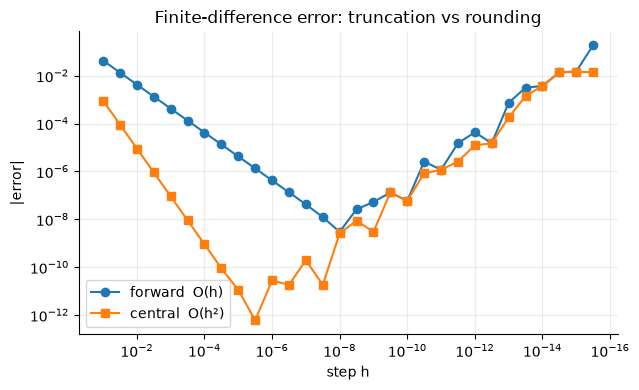

best forward h ≈ 1e-08  best central h ≈ 3.162277660168379e-06
  ✅ central difference reaches a smaller error than forward


In [2]:
f, fp = np.sin, np.cos
x0 = 1.0
hs = 10.0 ** np.arange(-1, -16, -0.5)
fwd = np.abs((f(x0 + hs) - f(x0)) / hs - fp(x0))
cen = np.abs((f(x0 + hs) - f(x0 - hs)) / (2 * hs) - fp(x0))
plt.loglog(hs, fwd, "o-", label="forward  O(h)"); plt.loglog(hs, cen, "s-", label="central  O(h²)")
plt.gca().invert_xaxis(); plt.xlabel("step h"); plt.ylabel("|error|"); plt.title("Finite-difference error: truncation vs rounding"); plt.legend()
show("finite_difference_error")
print("best forward h ≈", hs[fwd.argmin()], " best central h ≈", hs[cen.argmin()])
check(cen.min() < fwd.min(), "central difference reaches a smaller error than forward")
METRICS["best_central_error"] = cen.min()

## 2 · Gradients and level sets
For $f:\mathbb{R}^n\to\mathbb{R}$ the gradient $\nabla f$ points in the direction of steepest ascent and is **orthogonal to level sets**. Take $f(x,y)=x^2+3y^2+xy$; we plot contours and gradient arrows, and verify orthogonality by moving a tiny step *along* a level set.

  ✅ analytic gradient == central-difference gradient


15:57:49 | INFO | figure saved -> figures/gradient_field.png


/home/runner/work/deep-learning-systems/deep-learning-systems/notebooks/_common/dlsys.py:105: UserWarning: Glyph 10178 (\N{PERPENDICULAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/runner/work/deep-learning-systems/deep-learning-systems/notebooks/_common/dlsys.py:106: UserWarning: Glyph 10178 (\N{PERPENDICULAR}) missing from font(s) DejaVu Sans.
  plt.savefig(path, dpi=110, bbox_inches="tight")
/opt/hostedtoolcache/Python/3.12.16/x64/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10178 (\N{PERPENDICULAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


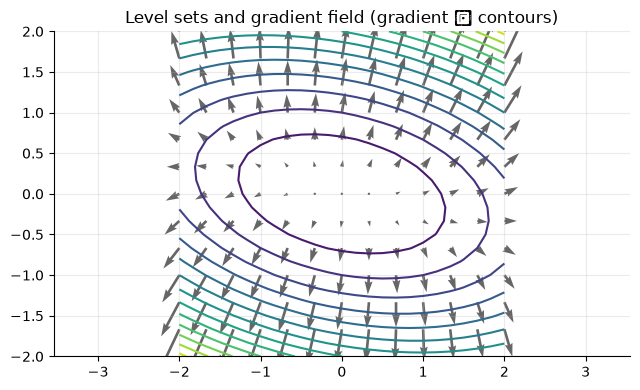

  ✅ moving along the tangent leaves f unchanged to first order


In [3]:
def f2(p): x, y = p; return x**2 + 3*y**2 + x*y
def g2(p): x, y = p; return np.array([2*x + y, 6*y + x])
def num_grad(f, p, h=1e-6):
    p = np.asarray(p, float); g = np.zeros_like(p)
    for i in range(p.size):
        e = np.zeros_like(p); e[i] = h
        g[i] = (f(p + e) - f(p - e)) / (2 * h)
    return g
p = np.array([1.0, -0.5])
check(np.allclose(g2(p), num_grad(f2, p), atol=1e-6), "analytic gradient == central-difference gradient")

X, Y = np.meshgrid(np.linspace(-2, 2, 25), np.linspace(-2, 2, 25)); Z = X**2 + 3*Y**2 + X*Y
G = np.stack([2*X + Y, 6*Y + X])
plt.contour(X, Y, Z, 15, cmap="viridis"); plt.quiver(X[::2, ::2], Y[::2, ::2], G[0][::2, ::2], G[1][::2, ::2], alpha=.6)
plt.title("Level sets and gradient field (gradient ⟂ contours)"); plt.axis("equal"); show("gradient_field")
g = g2(p); tangent = np.array([-g[1], g[0]]); tangent /= np.linalg.norm(tangent)
eps = 1e-4
check(abs(f2(p + eps * tangent) - f2(p)) < 1e-6, "moving along the tangent leaves f unchanged to first order")

## 3 · Jacobians, Hessians and Taylor expansion
For $F:\mathbb{R}^n\to\mathbb{R}^m$, $J_{ij}=\partial F_i/\partial x_j$ (shape $m\times n$). Example: polar → Cartesian $F(r,\theta)=(r\cos\theta,r\sin\theta)$ with $\det J=r$ (the area scaling factor).

The Hessian $H_{ij}=\partial^2f/\partial x_i\partial x_j$ gives the second-order Taylor model $f(x+\delta)\approx f(x)+\nabla f^\top\delta+\tfrac12\delta^\top H\delta$ whose error is $O(\|\delta\|^3)$.

  ✅ polar→Cartesian Jacobian matches finite differences
  ✅ det J = r


15:57:50 | INFO | figure saved -> figures/taylor_orders.png


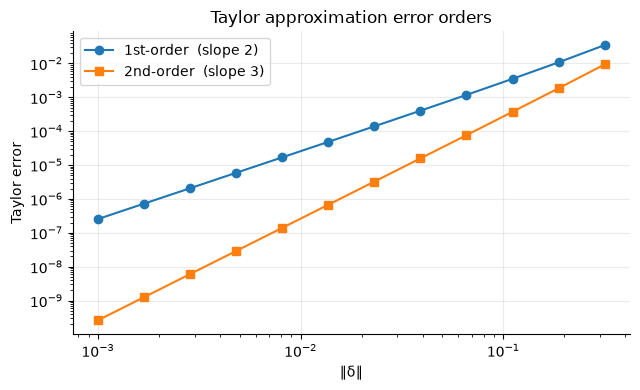

measured slopes: first-order 2.04, second-order 3.02
  ✅ Taylor error orders are 2 and 3, as theory predicts


In [4]:
def F(z): r, th = z; return np.array([r*np.cos(th), r*np.sin(th)])
def J_analytic(z): r, th = z; return np.array([[np.cos(th), -r*np.sin(th)], [np.sin(th), r*np.cos(th)]])
def num_jac(F, z, h=1e-6):
    z = np.asarray(z, float); cols = []
    for j in range(z.size):
        e = np.zeros_like(z); e[j] = h; cols.append((F(z + e) - F(z - e)) / (2*h))
    return np.stack(cols, 1)
z = np.array([2.0, 0.7])
check(np.allclose(J_analytic(z), num_jac(F, z), atol=1e-6), "polar→Cartesian Jacobian matches finite differences")
check(np.isclose(np.linalg.det(J_analytic(z)), z[0]), "det J = r")

# Taylor: f(x,y)=exp(x)*sin(y)
f3 = lambda p: np.exp(p[0]) * np.sin(p[1])
p0 = np.array([0.3, 0.8]); g0 = num_grad(f3, p0)
H0 = np.array([[np.exp(p0[0])*np.sin(p0[1]), np.exp(p0[0])*np.cos(p0[1])],
               [np.exp(p0[0])*np.cos(p0[1]), -np.exp(p0[0])*np.sin(p0[1])]])
scales = 10.0 ** np.linspace(-3, -0.5, 12); e1, e2 = [], []
d = np.array([1.0, -0.6])
for s_ in scales:
    dl = s_ * d; true = f3(p0 + dl)
    e1.append(abs(true - (f3(p0) + g0 @ dl))); e2.append(abs(true - (f3(p0) + g0 @ dl + .5 * dl @ H0 @ dl)))
plt.loglog(scales, e1, "o-", label="1st-order  (slope 2)"); plt.loglog(scales, e2, "s-", label="2nd-order  (slope 3)")
plt.xlabel("‖δ‖"); plt.ylabel("Taylor error"); plt.legend(); plt.title("Taylor approximation error orders"); show("taylor_orders")
sl1 = np.polyfit(np.log(scales), np.log(e1), 1)[0]; sl2 = np.polyfit(np.log(scales), np.log(e2), 1)[0]
print(f"measured slopes: first-order {sl1:.2f}, second-order {sl2:.2f}")
check(abs(sl1 - 2) < .2 and abs(sl2 - 3) < .3, "Taylor error orders are 2 and 3, as theory predicts")

## 4 · Reverse-mode autodiff from scratch
A computation is a directed acyclic **graph**. Forward pass: evaluate nodes, remembering how they were produced. Backward pass: seed $\bar y=1$ and propagate adjoints in reverse topological order using the chain rule: for $z=g(a,b)$,
$$\bar a \mathrel{+}= \bar z\,\frac{\partial g}{\partial a},\qquad \bar b \mathrel{+}= \bar z\,\frac{\partial g}{\partial b}.$$
Note the `+=`: a node used twice receives the **sum** of gradient contributions. Below is a ~40-line scalar engine.

In [5]:
import math
class Value:
    def __init__(self, data, parents=(), op=""):
        self.data, self.grad, self._parents, self._backward, self.op = float(data), 0.0, parents, lambda: None, op
    def __add__(s, o):
        o = o if isinstance(o, Value) else Value(o); out = Value(s.data + o.data, (s, o), "+")
        def _b(): s.grad += out.grad; o.grad += out.grad
        out._backward = _b; return out
    def __mul__(s, o):
        o = o if isinstance(o, Value) else Value(o); out = Value(s.data * o.data, (s, o), "*")
        def _b(): s.grad += o.data * out.grad; o.grad += s.data * out.grad
        out._backward = _b; return out
    def __pow__(s, k):
        out = Value(s.data ** k, (s,), f"**{k}")
        def _b(): s.grad += k * s.data ** (k - 1) * out.grad
        out._backward = _b; return out
    def exp(s):
        out = Value(math.exp(s.data), (s,), "exp")
        def _b(): s.grad += out.data * out.grad
        out._backward = _b; return out
    def tanh(s):
        t = math.tanh(s.data); out = Value(t, (s,), "tanh")
        def _b(): s.grad += (1 - t * t) * out.grad
        out._backward = _b; return out
    def log(s):
        out = Value(math.log(s.data), (s,), "log")
        def _b(): s.grad += out.grad / s.data
        out._backward = _b; return out
    __radd__ = __add__; __rmul__ = __mul__
    def __neg__(s): return s * -1
    def __sub__(s, o): return s + (-o if isinstance(o, Value) else Value(-o))
    def __truediv__(s, o): return s * (o if isinstance(o, Value) else Value(o)) ** -1
    def backward(s):
        topo, seen = [], set()
        def build(v):
            if v not in seen:
                seen.add(v); [build(p) for p in v._parents]; topo.append(v)
        build(s); s.grad = 1.0
        for v in reversed(topo): v._backward()

# f(x,y) = tanh(x*y + x^2) / (1 + exp(-y)) ; x is used twice -> gradients must accumulate
def f_val(x, y): return (x * y + x ** 2).tanh() / (1 + (-y).exp())
x, y = Value(0.7), Value(-0.4)
out = f_val(x, y); out.backward()
fn = lambda p: math.tanh(p[0]*p[1] + p[0]**2) / (1 + math.exp(-p[1]))
ng = num_grad(fn, [0.7, -0.4])
print("autodiff  :", x.grad, y.grad); print("numerical :", ng)
check(np.allclose([x.grad, y.grad], ng, atol=1e-6), "from-scratch autodiff == finite differences")

autodiff  : 0.38412207283111793 0.3186113765502948
numerical : [0.38412207 0.31861138]
  ✅ from-scratch autodiff == finite differences


### Compare with PyTorch autograd
PyTorch builds the same kind of graph dynamically. We check that it agrees with our engine to machine precision.

In [6]:
xt = torch.tensor(0.7, dtype=torch.float64, requires_grad=True); yt = torch.tensor(-0.4, dtype=torch.float64, requires_grad=True)
ot = torch.tanh(xt * yt + xt ** 2) / (1 + torch.exp(-yt)); ot.backward()
print("torch grads:", xt.grad.item(), yt.grad.item())
check(np.allclose([x.grad, y.grad], [xt.grad.item(), yt.grad.item()], atol=1e-12), "our engine == torch.autograd")

torch grads: 0.38412207283111793 0.3186113765502948
  ✅ our engine == torch.autograd


## 5 · VJP vs JVP and matrix calculus
For $F:\mathbb{R}^n\to\mathbb{R}^m$: a **JVP** computes $Jv$ (forward mode, one pass per *input* direction); a **VJP** computes $u^\top J$ (reverse mode, one pass per *output*). Deep learning has $m=1$ (a scalar loss) and huge $n$, so reverse mode gets the full gradient in one pass — that's backpropagation.

Matrix example: $L(x)=\|Ax-b\|^2\Rightarrow\nabla L=2A^\top(Ax-b)$; for $Y=XW$, $\bar W=X^\top\bar Y$ and $\bar X=\bar YW^\top$ (shapes are the best guide!).

In [7]:
rng = np.random.default_rng(1)
A, b, x = rng.normal(size=(6, 4)), rng.normal(size=6), rng.normal(size=4)
L = lambda x: np.sum((A @ x - b) ** 2)
check(np.allclose(2 * A.T @ (A @ x - b), num_grad(L, x), atol=1e-5), "∇‖Ax−b‖² = 2Aᵀ(Ax−b)")

# Y = X W, loss = sum(Y * G) for fixed random G  -> dL/dY = G
X_, W_, G_ = rng.normal(size=(5, 3)), rng.normal(size=(3, 2)), rng.normal(size=(5, 2))
dW, dX = X_.T @ G_, G_ @ W_.T
numW = np.zeros_like(W_)
for i in range(3):
    for j in range(2):
        E = np.zeros_like(W_); E[i, j] = 1e-6
        numW[i, j] = (np.sum((X_ @ (W_ + E)) * G_) - np.sum((X_ @ (W_ - E)) * G_)) / 2e-6
check(np.allclose(dW, numW, atol=1e-5), "dL/dW = Xᵀ·dL/dY verified")
check(dW.shape == W_.shape and dX.shape == X_.shape, "adjoints have the same shape as the primal variables")

# JVP via finite differences vs VJP via transpose: <u, Jv> == <J^T u, v>
Jm = num_jac(lambda z: np.tanh(A @ z), x); v, u = rng.normal(size=4), rng.normal(size=6)
check(np.isclose(u @ (Jm @ v), (Jm.T @ u) @ v), "adjoint identity ⟨u, Jv⟩ = ⟨Jᵀu, v⟩")
t = torch.tensor(x, requires_grad=True)
y_ = torch.tanh(torch.tensor(A) @ t); (y_ @ torch.tensor(u)).backward()
check(np.allclose(t.grad.numpy(), Jm.T @ u, atol=1e-5), "torch VJP == Jᵀu")

  ✅ ∇‖Ax−b‖² = 2Aᵀ(Ax−b)
  ✅ dL/dW = Xᵀ·dL/dY verified
  ✅ adjoints have the same shape as the primal variables
  ✅ adjoint identity ⟨u, Jv⟩ = ⟨Jᵀu, v⟩
  ✅ torch VJP == Jᵀu


In [8]:
save_metrics("02", METRICS)
log.info('notebook 02 finished OK')

15:57:50 | INFO | metrics saved -> metrics.json


15:57:50 | INFO | notebook 02 finished OK


## Wrap-up

## Exercises (do these next)

1. Add `sin` and `relu` to the `Value` class and gradient-check a small MLP built from `Value`s.
2. Estimate the Hessian by finite differences of gradients and compare with the analytic one in section 3.
3. Use `torch.autograd.functional.jacobian` and `hessian` on the polar example.

## Where to read more

- Wiki chapter: [Module 02](https://github.com/anuxlab/deep-learning-systems/wiki/Module-02) (derivations, worked example, Q&A).
- Baydin et al. (2018), *Automatic differentiation in machine learning: a survey*.
- Karpathy's *micrograd* (the inspiration for section 4).